In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from imblearn.over_sampling import SMOTE

Shape: (4997, 141)
Columns: Index(['-0.11252183', '-2.8272038', '-3.7738969', '-4.3497511', '-4.376041',
       '-3.4749863', '-2.1814082', '-1.8182865', '-1.2505219', '-0.47749208',
       ...
       '0.79216787', '0.93354122', '0.79695779', '0.57862066', '0.2577399',
       '0.22807718', '0.12343082', '0.92528624', '0.19313742', '1.0'],
      dtype='object', length=141)
Target column: 1.0


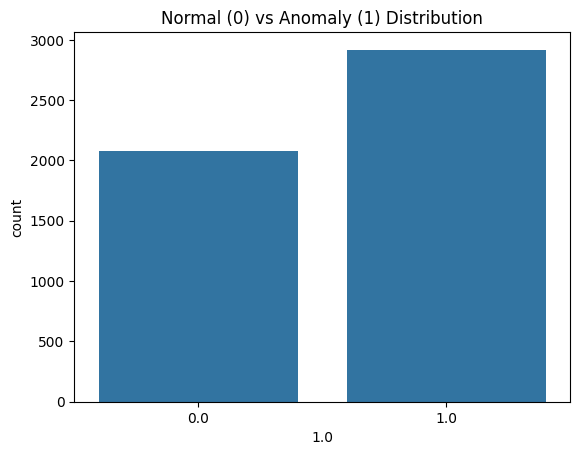

In [4]:
# Load ECG dataset

data = pd.read_csv("ecg.csv")

# Drop rows with NaN values
data.dropna(inplace=True)

print("Shape:", data.shape)
print("Columns:", data.columns)

# Target column is the last one
target_col = data.columns[-1]
print("Target column:", target_col)

X = data.drop(target_col, axis=1).values
y = data[target_col].values
sns.countplot(x=target_col, data=data)
plt.title("Normal (0) vs Anomaly (1) Distribution")
plt.show()

In [7]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Balance dataset using SMOTE (only training data)
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", np.bincount(y_train.astype(int)))
print("After SMOTE :", np.bincount(y_train_bal.astype(int)))

Before SMOTE: [1669 2328]
After SMOTE : [2328 2328]


In [8]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Train Shape:", X_train_scaled.shape)
print("Test Shape:", X_test_scaled.shape)

Train Shape: (3997, 140)
Test Shape: (1000, 140)


In [9]:
input_dim = X_train_scaled.shape[1]

In [10]:
autoencoder = models.Sequential([
    layers.Input(shape=(input_dim,)),      # Input layer

    # Encoder
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),

    # Bottleneck
    layers.Dense(8, activation="relu"),

    # Decoder
    layers.Dense(16, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(64, activation="relu"),

    # Output (same size as input)
    layers.Dense(input_dim, activation="sigmoid")  # works with MinMaxScaler
])

In [11]:
# Compile
autoencoder.compile(optimizer=Adam(learning_rate=0.001),
                    loss="mse",
                    metrics=["mae"])

autoencoder.summary()
# Print model summary (layers, params)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,668 (92.45 KB)

 Trainable params: 23,668 (92.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0304 - mae: 0.1475 - val_loss: 0.0286 - val_mae: 0.1412
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0251 - mae: 0.1293 - val_loss: 0.0214 - val_mae: 0.1143
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0184 - mae: 0.1050 - val_loss: 0.0158 - val_mae: 0.0952
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0139 - mae: 0.0887 - val_loss: 0.0129 - val_mae: 0.0838
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0118 - mae: 0.0797 - val_loss: 0.0117 - val_mae: 0.0778
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0109 - mae: 0.0750 - val_loss: 0.0111 - val_mae: 0.0746
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0105 - mae: 0.0726 - val_loss: 0.0109 - val_mae: 0.0730
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0103 - mae: 0.0715 - val_loss: 0.0108 - val_mae: 0.0724
Epoch 9/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0102 - mae: 0.0711 - 

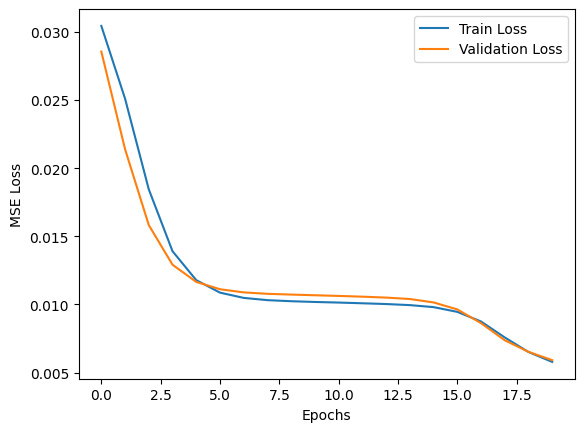

In [12]:
#train
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',  # Monitor validation loss
    patience=5,          # Number of epochs with no improvement after which training will be stopped.
    restore_best_weights=True # Restore model weights from the epoch with the best value of the monitored quantity.
)

history = autoencoder.fit(
    X_train_scaled, X_train_scaled,
    epochs=20, batch_size=512,
    validation_data=(X_test_scaled, X_test_scaled),
    callbacks=[early_stopping], # Add early stopping callback
    verbose=1
)
plt.plot(history.history['loss'], label="Train Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

In [13]:
# Get predictions
X_train_pred = autoencoder.predict(X_train_scaled)
X_test_pred = autoencoder.predict(X_test_scaled)

# Reconstruction errors
#error = (original - reconstructed)^2
train_errors = np.mean(np.square(X_train_scaled - X_train_pred), axis=1)
test_errors = np.mean(np.square(X_test_scaled - X_test_pred), axis=1)

# Threshold (mean + std of training error)
threshold = np.mean(train_errors) + np.std(train_errors)
print("Reconstruction Threshold:", threshold)

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Reconstruction Threshold: 0.011682630517843023


Accuracy: 0.385


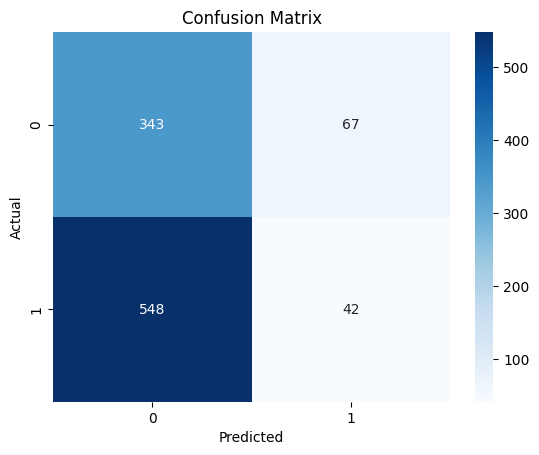

In [14]:
# Predict anomalies
y_pred = [1 if e > threshold else 0 for e in test_errors]

# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()